# MODELIZACIÓN REGRESIÓN EXPOSURE AT DEFAULT

## IMPORTAR PAQUETES

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
import os
from pathlib import Path
import openpyxl
import sqlalchemy as sa

# Desactivar notación científica
pd.set_option('display.float_format', lambda x: '%.3f' % x)
np.set_printoptions(suppress=True)

#RUTAS
# ── Rutas del proyecto ────────────────────────────────────────────────
# Se resuelven desde la ubicación del notebook, así funcionan
# igual en cualquier máquina
RAIZ = Path.cwd().parent

ORIGINALES   = RAIZ / '02_datos' / '01_Originales'
VALIDACION   = RAIZ / '02_datos' / '02_Validacion'
ENTRENAMIENTO = RAIZ / '02_datos' / '03_Entrenamiento'
CACHES       = RAIZ / '02_datos' / '04_Caches'
MODELOS      = RAIZ / '05_modelos'
RESULTADOS   = RAIZ / '06_resultados'

# ----------USO DE UTILS.PY------------
import sys
from pathlib import Path
# Subir de 03_notebooks a 03_RIESGOS
ROOT = Path.cwd().parent
# Añadir 04_scripts a las rutas de búsqueda
sys.path.insert(0, str(ROOT / "04_scripts"))
#---------------------------------------

# Cargar variables de entorno
load_dotenv()

print("✅ Librerías importadas correctamente")

✅ Librerías importadas correctamente


## MODELIZACIÓN REGRESION EXPOSURE AT DEFAULT

### IMPORTAR LOS DATOS

In [42]:
df = pd.read_pickle(ENTRENAMIENTO / "df_tablon_ead.pkl")

### CREAR X e Y

In [43]:
from sklearn.model_selection import train_test_split

x = df.drop(columns=["target_ead","target_pd"])
y = df["target_ead"]
x_train,x_test,y_train,y_val = train_test_split(x, y, test_size=0.3, random_state=42)

### MODELIZAR

#### Crear el pipe y el diccionario de algorimos, parámetros y valores a testar

In [44]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import HistGradientBoostingRegressor

pipe = Pipeline([('algoritmo', Ridge())])   # el nombre del paso es solo una etiqueta fija

grid = [
    {'algoritmo': [Ridge()],
     'algoritmo__alpha': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]},

    {'algoritmo': [Lasso()],
     'algoritmo__alpha': [0.0001, 0.001, 0.01, 0.05, 0.1]},

    # min_samples_leaf=100: hojas con al menos 100 casos, evita sobreajuste
    # scoring: métrica de la parada temprana, no la del grid
    {'algoritmo': [HistGradientBoostingRegressor(min_samples_leaf=60,
                                                 scoring='neg_mean_absolute_error')],
     'algoritmo__learning_rate': [0.01, 0.025, 0.05, 0.1],
     'algoritmo__max_iter': [50, 100, 200],
     'algoritmo__max_depth': [5, 10, 20],
     'algoritmo__l2_regularization': [0, 0.25, 0.5, 0.75, 1]}
]

#### Optimizar los hiper parámetros

#####  Con grid search

In [45]:
from sklearn.model_selection import GridSearchCV
grid_search = GridSearchCV(pipe, grid, cv=4, scoring='neg_mean_absolute_error', n_jobs=-1)
modelo = grid_search.fit(x_train, y_train)

In [46]:
#quiero tomar los parametros del mejor modelo para usarlo en un nuevo modelo
grid_search.best_params_

{'algoritmo': HistGradientBoostingRegressor(min_samples_leaf=60,
                               scoring='neg_mean_absolute_error'),
 'algoritmo__l2_regularization': 0,
 'algoritmo__learning_rate': 0.1,
 'algoritmo__max_depth': 5,
 'algoritmo__max_iter': 200}

In [47]:
modelo_ead = HistGradientBoostingRegressor(learning_rate=0.05, l2_regularization=0.25, max_depth=5, max_iter=200, min_samples_leaf=60, scoring='neg_mean_absolute_error')
modelo_ead.fit(x_train, y_train)

,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.05
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",200
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",5
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",60
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.25
,"scoring scoring: str or callable or None, default='loss'Scoring method to use for early stopping. Only used if `early_stopping`is enabled. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: the :ref:`coefficient of determination <r2_score>` (:math:`R^2`) is used.- 'loss': early stopping is checked w.r.t the loss value.",'neg_mean_absolute_error'
,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


### EVALUAR

#### Predecir sobre validación

In [48]:
pred = modelo_ead.predict(x_test)

Al ser un modelo de regresion y estar en porcentaje la variable objetivo no tendria sentido que
tuviera valores por encima de los limites, pero, de todas formas se eliminan los maximos y minimos por si acaso

In [49]:
pred = np.where(pred < 0, 0, pred)  # reemplazar predicciones negativas por 0
pred = np.where(pred > 1, 1, pred)  # reemplazar predicciones mayores a 1 por 1

#### Evaluar sobre validación

In [50]:
from sklearn.metrics import mean_absolute_error
mean_absolute_error(y_val, pred)

0.15723231206261118

### REPORTING DEL MODELO

In [51]:
check_validation = pd.DataFrame({"y_val": y_val, "pred": pred})
check_validation

,y_val,pred
id_cliente,,
56051627,0.487,0.610
109923302,0.759,0.858
1486619,0.751,0.762
7367379,0.865,0.725
86031234,0.882,0.830
...,...,...
6726625,0.656,0.713
130533642,0.888,0.721
1247820,0.769,0.634


Podemos analizarlo gráficamente con gráficos de residuos.

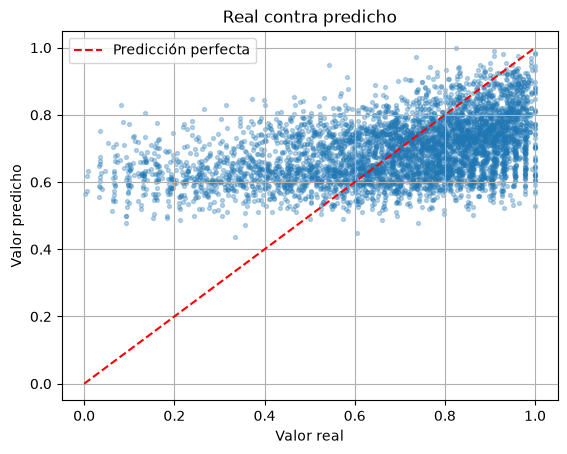

,casos,real_medio,pred_medio,error_medio
target_ead,,,,
"(-0.001, 0.2]",188,0.125,0.624,0.499
"(0.2, 0.4]",391,0.312,0.631,0.319
"(0.4, 0.6]",813,0.512,0.661,0.151
"(0.6, 0.8]",1582,0.709,0.686,0.075
"(0.8, 1.0]",1991,0.894,0.737,0.161


In [52]:
plt.scatter(y_val, pred, alpha=0.3, s=8)
plt.plot([0, 1], [0, 1], 'r--', label='Predicción perfecta')
plt.xlabel('Valor real'); plt.ylabel('Valor predicho')
plt.title('Real contra predicho'); plt.legend(); plt.grid(True)
plt.show()

tramos = pd.cut(y_val, [0, 0.2, 0.4, 0.6, 0.8, 1.0], include_lowest=True)
(pd.DataFrame({'real': y_val, 'pred': pred, 'error_abs': (y_val - pred).abs()})
   .groupby(tramos, observed=True)
   .agg(casos=('real', 'size'), real_medio=('real', 'mean'),
        pred_medio=('pred', 'mean'), error_medio=('error_abs', 'mean'))
   .round(3))

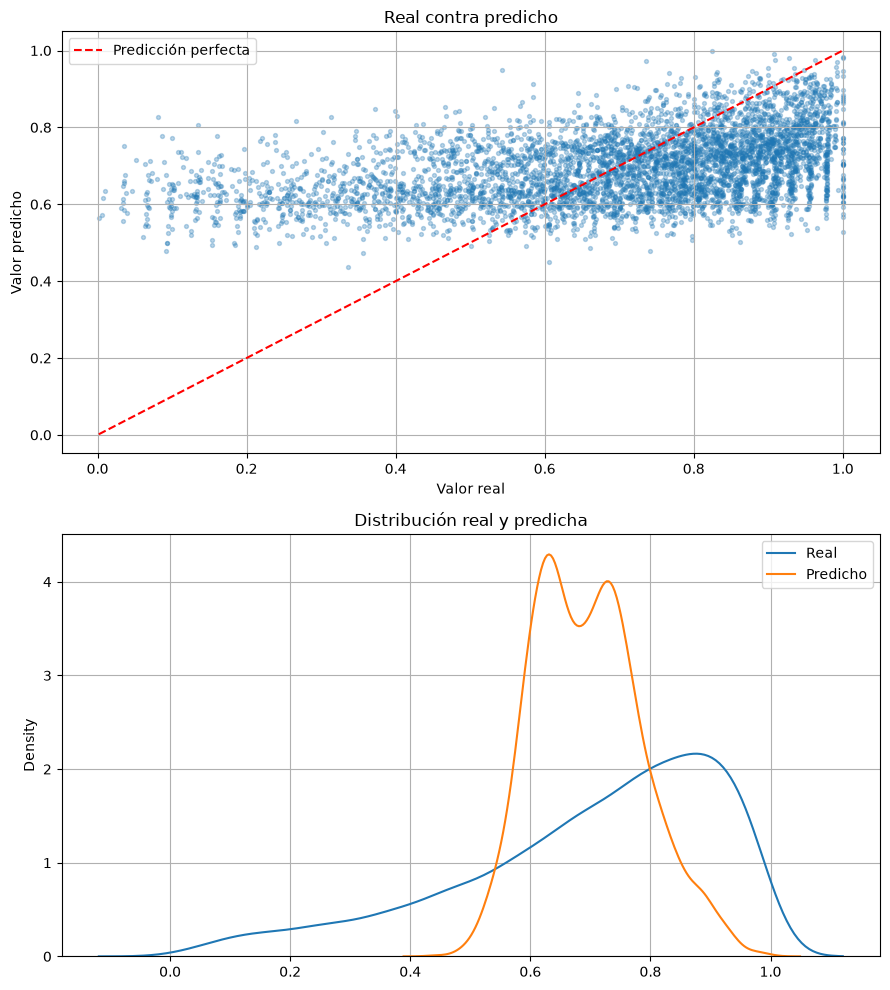

MAE: 0.157  |  error medio sobre el real medio: 22.5%


,casos,real_medio,pred_medio,error_medio
"(0.00068, 0.519]",993,0.340,0.641,0.301
"(0.519, 0.689]",993,0.613,0.670,0.082
"(0.689, 0.8]",993,0.747,0.695,0.081
"(0.8, 0.893]",993,0.848,0.722,0.133
"(0.893, 1.0]",993,0.941,0.752,0.190


In [53]:
import importlib, utils
importlib.reload(utils)
from utils import reporting_regresion
reporting_regresion(y_val, pred)

### Cómo leer estos gráficos

**Real contra predicho.** Cada punto es un préstamo. Abajo está lo que el cliente debía de verdad cuando falló, y a la izquierda lo que el modelo predijo. Si el modelo acertara, los puntos caerían sobre la diagonal roja. Aquí forman una franja casi horizontal entre el 60 % y el 80 %: el modelo predice casi lo mismo para todos.

**Densidad real y predicha.** La curva real es ancha porque hay préstamos que se debían casi por completo y otros casi nada. La curva predicha es estrecha y está en el centro, cerca del 70 %. Esa diferencia de anchura muestra que el modelo se concentra en un valor típico y no llega a los extremos.

**Tabla por tramos.** Un cliente que debía muy poco (13 % en promedio) aparece con una predicción cercana al 63 %. Uno que debía casi todo (89 %) aparece con cerca de 73 %. Donde más se equivoca es en los que debían poco, y ahí el modelo se pasa (lado prudente). En los que debían casi todo se queda corto, que es el lado que más pérdida puede traer.

**Por qué pasa.** Con las variables que se conocen al conceder el préstamo, el modelo no puede saber cuánto habrá pagado el cliente antes de fallar. Cuando no hay información suficiente, predice un valor típico.

**Cómo usarlo.** Sirve para ordenar el riesgo de forma aproximada y es fiable en los casos típicos, pero no para fijar el monto exacto de un cliente en los extremos.

In [54]:
df['target_ead'].describe().T

count   16549.000
mean        0.695
std         0.219
min         0.000
25%         0.566
50%         0.745
75%         0.869
max         1.000
Name: target_ead, dtype: float64